# ISYE 4031 — Angelo: Preliminary Exploration

Uses Michael’s already-cleaned Excel datasets. Includes one scatterplot, one missing-values table, and short interpretations for the project proposal.

**Run in Google Colab:**
1. Extract Michael’s data ZIP on your computer.
2. Upload `epl_match_data.xlsx` and `epl_transfer_data.xlsx` using Colab’s **Files sidebar → Upload**. Place both in the main session folder.
3. Run the cells below in order, or choose **Runtime → Run all**.

Michael’s download and cleaning sections are not needed here. Files must be uploaded again if the Colab session resets.

### A. Load Michael’s cleaned Excel files

In [2]:
# IMPORTS AND DATA SETUP
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

epl_match_data = pd.read_excel("epl_match_data.xlsx", sheet_name="Match Data")
epl_transfer_data = pd.read_excel("epl_transfer_data.xlsx")

print(f"Match observations: {len(epl_match_data):,}")
print(f"Transfer observations: {len(epl_transfer_data):,}")

Match observations: 8,360
Transfer observations: 6,090


### B. Figure 1: Points after ten matches vs. final season points
Sort matches chronologically within each club-season, then sum the first ten match results. Calculate final points from all match results. Use only club-seasons with 38 matches. “Final points” here means match-earned points; official standings may also reflect administrative deductions.

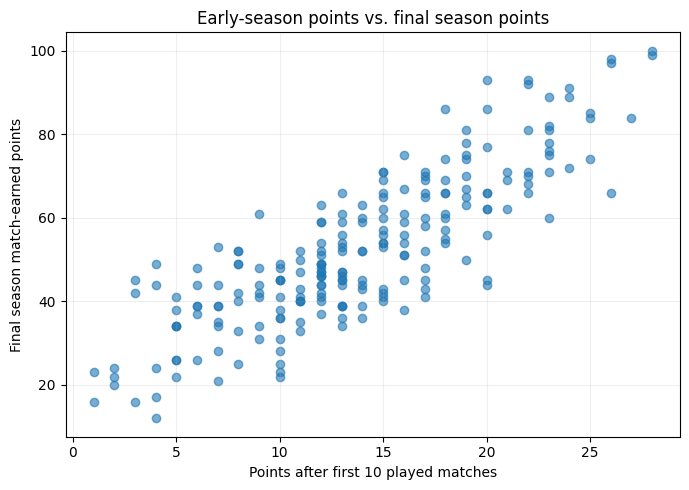

Complete club-seasons: 220
Correlation: 0.836


In [3]:
# FIRST-TEN-MATCH POINTS AND FINAL POINTS
matches = epl_match_data.copy()
matches["Date"] = pd.to_datetime(matches["Date"])
matches = matches.sort_values(["Season", "Team", "Date", "Match_ID"])
keys = ["Season", "Team"]
matches["Match_Number"] = matches.groupby(keys).cumcount() + 1

early_points = matches[matches["Match_Number"] <= 10].groupby(keys)["Points"].sum()
season_summary = matches.groupby(keys).agg(
    Final_Points=("Points", "sum"), Matches=("Points", "size")
)
exploration = season_summary.join(early_points.rename("Points_After_10"))
exploration = exploration[exploration["Matches"] == 38]
correlation = exploration["Points_After_10"].corr(exploration["Final_Points"])

plt.figure(figsize=(7, 5))
plt.scatter(exploration["Points_After_10"], exploration["Final_Points"], alpha=0.6)
plt.xlabel("Points after first 10 played matches")
plt.ylabel("Final season match-earned points")
plt.title("Early-season points vs. final season points")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.savefig("angelo_figure1.png", dpi=200)
plt.show()
print(f"Complete club-seasons: {len(exploration)}")
print(f"Correlation: {correlation:.3f}")

**Figure 1 interpretation:** Across 220 complete club-seasons, points earned in the first ten matches have a strong positive association with final season points (correlation = 0.836). Teams with stronger starts generally finish with more points, suggesting that early-season points may be a useful predictor. However, teams with similar starts can have different final totals. The first ten matches also contribute directly to the final total, so this relationship alone does not establish forecasting accuracy.

### C. Table 1: Missing transfer information
Use Michael’s existing missing-value flags to summarize missing fees and market values.

In [4]:
# SMALL MISSINGNESS SUMMARY
missing_table = pd.DataFrame({
    "Transfer variable": ["Transfer fee", "Player market value"],
    "Missing records": [
        int(epl_transfer_data["Fee_Missing"].sum()),
        int(epl_transfer_data["Market_Value_Missing"].sum())
    ]
})
missing_table["Missing (%)"] = (
    100 * missing_table["Missing records"] / len(epl_transfer_data)
).round(2)
display(missing_table)
print("Missing values in original match data:", int(epl_match_data.isna().sum().sum()))

,Transfer variable,Missing records,Missing (%)
0,Transfer fee,412,6.77
1,Player market value,249,4.09


Missing values in original match data: 0


**Table 1 interpretation:** Of the 6,090 transfer records, 412 transfer fees (6.77%) and 249 player market values (4.09%) are missing. These missing amounts should not be assumed to equal zero. The match data have no missing values in the supplied dataset.

**Data quality and dependence:** The same clubs appear across multiple seasons, and each physical match appears twice in the raw data, once for each team. The figure uses one observation per club-season, but club-season observations are still not fully independent. Club names will need to be reconciled before combining the match and transfer datasets. At the proposed prediction point after ten played matches, predictors should use only information available by that point, excluding later matches and winter transfers. Transfer fee and market-value coverage will need further review before financial predictors are used.